In [ ]:
Analisis Data Kebiasaan dan Performa Mahasiswa (Student Habits & Performance)

Gambaran Umum
Analisis ini memakai dataset kebiasaan mahasiswa, seperti jam belajar, jam media sosial, dan jam menonton Netflix. Tujuannya adalah menyiapkan data agar bersih dan siap dianalisis, lalu melihat pola serta hubungan antarvariabel. Prosesnya terdiri dari tiga tahap: pemuatan data, pembersihan dan transformasi data (data preprocessing), dan eksplorasi data (EDA).

In [ ]:
Tahap 1: Pemuatan Data (Data Loading)

Langkah 1 - Membaca dataset.
Library pandas digunakan untuk membaca file Student_Habits_Performance.csv ke dalam DataFrame. Data dimuat ke dua variabel, test dan train, lalu fungsi head() menampilkan lima baris pertama untuk memastikan data terbaca dengan benar dan struktur kolomnya sesuai harapan.

In [1]:
# DATA LOADING
import pandas as pd
test = pd.read_csv("Student_Habits_Performance.csv")
test.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [2]:
train = pd.read_csv("Student_Habits_Performance.csv")
train.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [ ]:
Tahap 2: Pembersihan Data (Data Cleaning)

Langkah 2 - Memeriksa informasi dataset.
Fungsi info() menampilkan jumlah baris, nama kolom, tipe data, dan jumlah data yang terisi pada tiap kolom. Dari sini terlihat kolom mana yang numerik dan mana yang kategorikal, serta indikasi awal adanya data kosong.

In [3]:
# DATA CLEANING
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   object 
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   object 
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   object 
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   object 
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    object 
 12  internet_quality               1000 non-null   ob

In [ ]:
Langkah 3 - Melihat statistik deskriptif.
Fungsi describe(include="all") meringkas data numerik (rata-rata, standar deviasi, minimum, maksimum, kuartil) dan data kategorikal (jumlah kategori unik dan nilai yang paling sering muncul). Ringkasan ini memberi gambaran awal tentang sebaran dan rentang nilai.

In [4]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
count,1000,1000.0000,1000,1000.00000,1000.000000,1000.000000,1000,1000.000000,1000.000000,1000,1000.000000,909,1000,1000.000000,1000,1000.000000
unique,1000,NaN,3,NaN,NaN,NaN,2,NaN,NaN,3,NaN,3,3,NaN,2,NaN
top,S1000,NaN,Female,NaN,NaN,NaN,No,NaN,NaN,Fair,NaN,High School,Good,NaN,No,NaN
freq,1,NaN,481,NaN,NaN,NaN,785,NaN,NaN,437,NaN,392,447,NaN,682,NaN
mean,NaN,20.4980,NaN,3.55010,2.505500,1.819700,NaN,84.131700,6.470100,NaN,3.042000,NaN,NaN,5.438000,NaN,69.601500
std,NaN,2.3081,NaN,1.46889,1.172422,1.075118,NaN,9.399246,1.226377,NaN,2.025423,NaN,NaN,2.847501,NaN,16.888564
min,NaN,17.0000,NaN,0.00000,0.000000,0.000000,NaN,56.000000,3.200000,NaN,0.000000,NaN,NaN,1.000000,NaN,18.400000
25%,NaN,18.7500,NaN,2.60000,1.700000,1.000000,NaN,78.000000,5.600000,NaN,1.000000,NaN,NaN,3.000000,NaN,58.475000
50%,NaN,20.0000,NaN,3.50000,2.500000,1.800000,NaN,84.400000,6.500000,NaN,3.000000,NaN,NaN,5.000000,NaN,70.500000
75%,NaN,23.0000,NaN,4.50000,3.300000,2.525000,NaN,91.025000,7.300000,NaN,5.000000,NaN,NaN,8.000000,NaN,81.325000


In [ ]:
Langkah 4 - Memeriksa nilai yang hilang (missing values).
Fungsi isnull().sum() menghitung data kosong di setiap kolom, dan hanya kolom yang memiliki data kosong yang ditampilkan.

In [5]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

parental_education_level    91
dtype: int64

In [ ]:
Langkah 5 - Menentukan strategi penanganan missing value.
Kolom dibagi dua berdasarkan ambang batas 750 data kosong:
less: kolom dengan data kosong kurang dari 750, yang masih layak diisi.
over: kolom dengan data kosong 750 atau lebih, yang terlalu banyak kehilangan data sehingga dihapus.

In [6]:
# Mengatasi missing value
less = missing_values[missing_values < 750].index
over = missing_values[missing_values >= 750].index

In [ ]:
Langkah 6 - Mengisi data kosong pada kolom numerik.
Kolom numerik pada kelompok less diisi dengan median. Median dipilih karena tidak terpengaruh nilai ekstrem, sehingga lebih aman dibanding rata-rata.

In [7]:
# Mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train [numeric_features].fillna(train[numeric_features].median())

In [ ]:
Langkah 7 - Mengisi data kosong pada kolom kategorikal.
Kolom kategorikal pada kelompok less diisi dengan modus, yaitu kategori yang paling sering muncul.

In [8]:
# Mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [ ]:
Langkah 8 - Menghapus kolom dengan terlalu banyak data kosong.
Kolom kelompok over dihapus dengan drop(), dan hasilnya disimpan dalam DataFrame baru bernama df. Imputasi pada kolom yang hampir kosong dapat menimbulkan bias.

In [9]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [ ]:
Langkah 9 - Verifikasi.
Pemeriksaan missing value diulang pada df untuk memastikan tidak ada data kosong yang tersisa.

In [10]:
# Memeriksa data yang sudah melewati tahapan verifikasi missing value
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [ ]:
Tahap 3: Penanganan Outlier

Langkah 10 - Visualisasi dengan box plot.
Setiap fitur numerik divisualisasikan dengan box plot menggunakan seaborn. Titik di luar “kumis” (whisker) menunjukkan nilai yang berpotensi menjadi outlier.

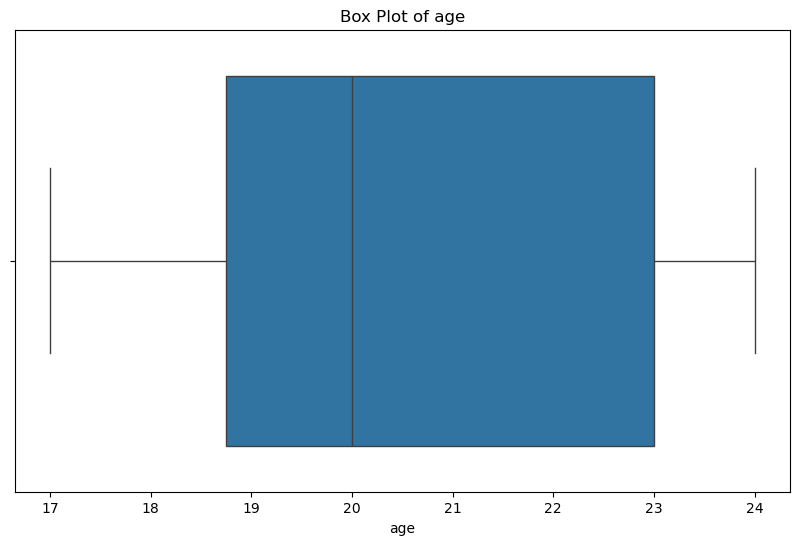

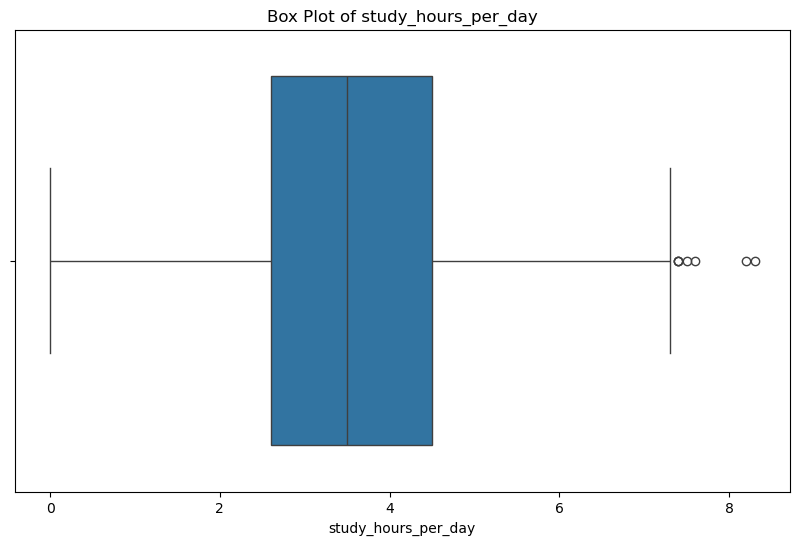

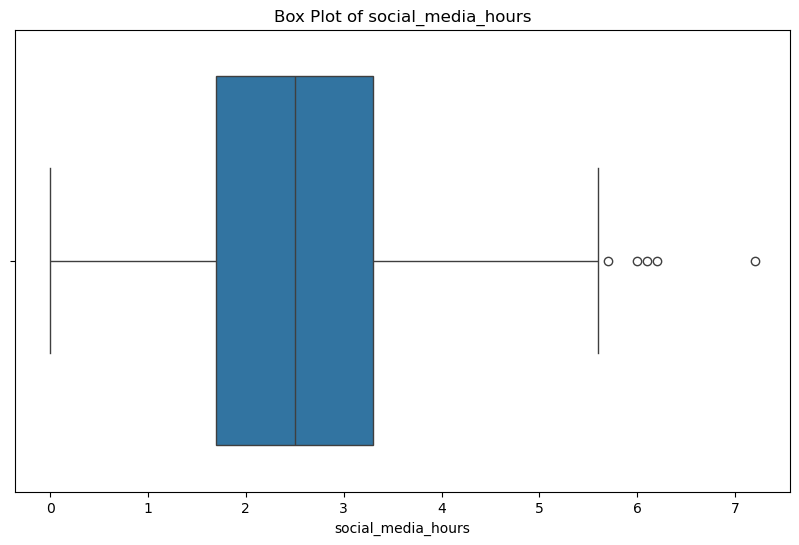

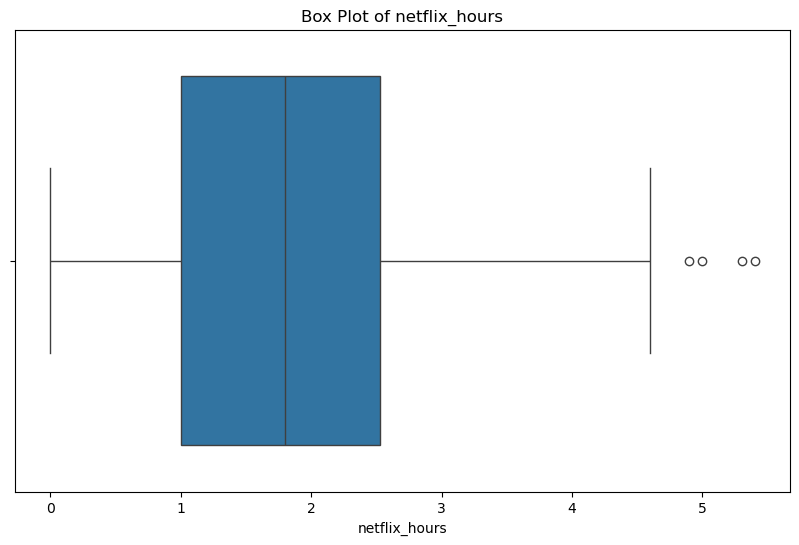

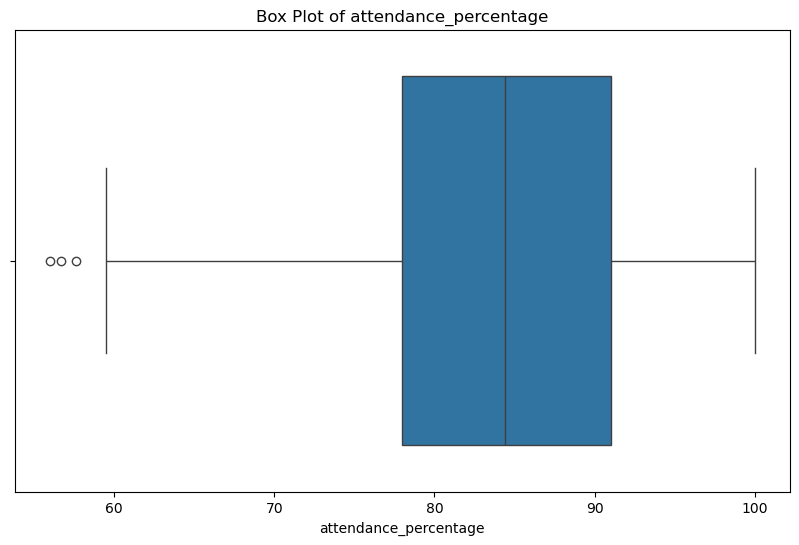

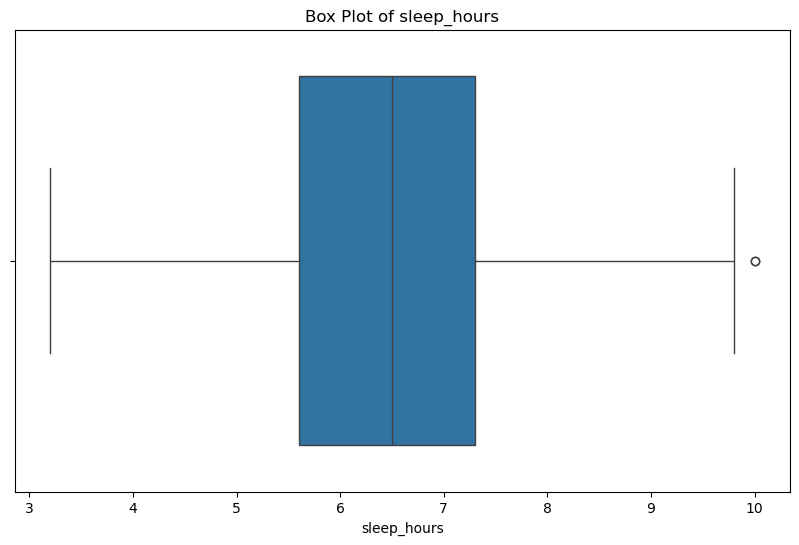

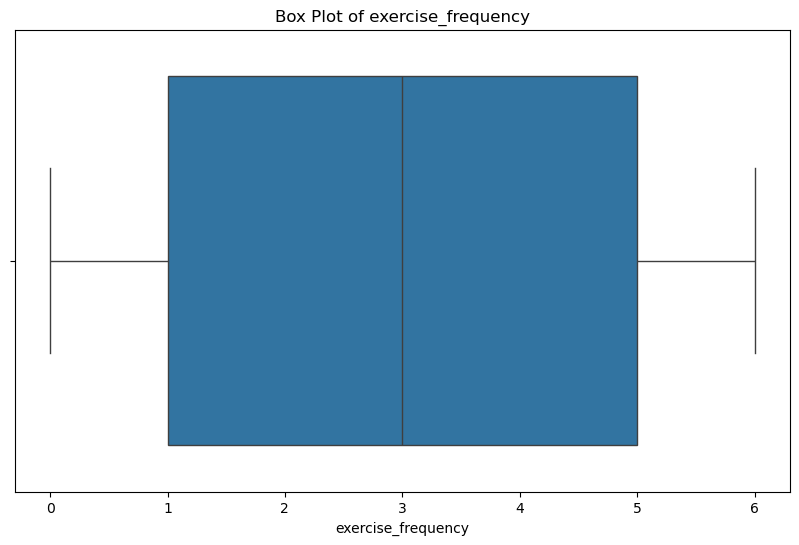

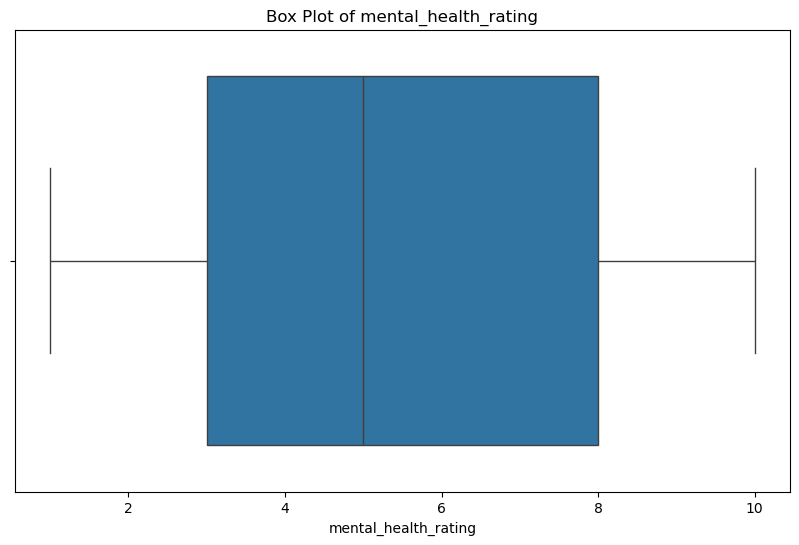

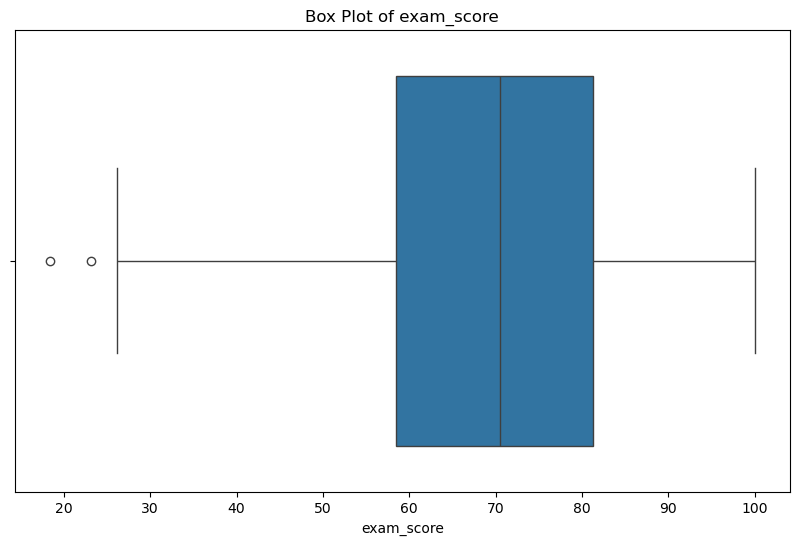

In [11]:
# Mengatasi Outliers
import pandas as ps
import seaborn as sns
import matplotlib.pyplot as plt
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [ ]:
Langkah 11 - Menghitung batas outlier dengan metode IQR.
Kuartil pertama (Q1), kuartil ketiga (Q3), dan Interquartile Range (IQR = Q3 - Q1) dihitung untuk setiap fitur numerik. Data dianggap outlier jika berada di bawah Q1 - 1,5xIQR atau di atas Q3 + 1,5×IQR.

In [12]:
# Mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [ ]:
Tahap 4: Standardisasi Data

Langkah 12 - Standardisasi fitur numerik.
StandardScaler mengubah fitur numerik sehingga memiliki rata-rata 0 dan standar deviasi 1. Metode ini dipilih karena distribusi data mendekati normal dan tidak perlu dibatasi pada rentang 0–1. Standardisasi membuat variabel dengan satuan berbeda, seperti usia dan jam belajar, berada pada skala yang sebanding.

In [13]:
# Standardisasi untuk distribusi normal dan tidak membutuhkan 0-1
from sklearn.preprocessing import StandardScaler
# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

In [ ]:
Langkah 13 - Membandingkan sebelum dan sesudah standardisasi.
Dua histogram disandingkan untuk satu fitur numerik: satu dari data asli (train) dan satu dari data terstandardisasi (df). Bentuk distribusinya sama, tetapi skala sumbu berubah dan berpusat di sekitar nol.

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

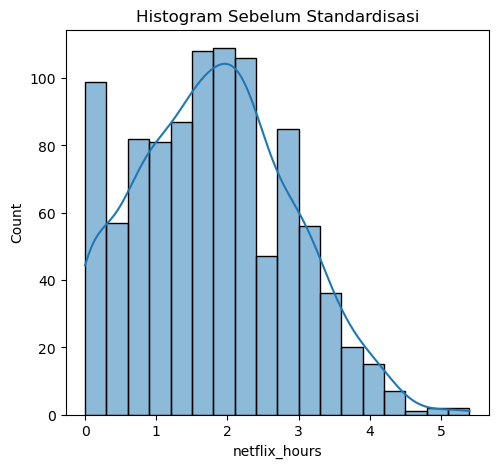

In [14]:
# Melakukan  perbandingan antara data sebelum dan sesudah dilakukan standardisasi
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

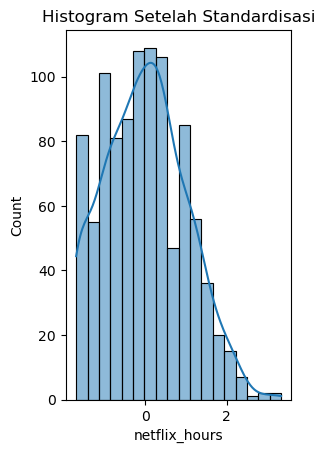

In [15]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [ ]:
Tahap 5: Penanganan Data Duplikat

Langkah 14 - Mengecek baris duplikat.
Fungsi duplicated() mengidentifikasi baris yang identik. Baris duplikat dapat membuat sebagian data terhitung berulang dan memengaruhi hasil analisis.

In [16]:
# MENANGANI DUPLIKASI DATA
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [student_id, age, gender, study_hours_per_day, social_media_hours, netflix_hours, part_time_job, attendance_percentage, sleep_hours, diet_quality, exercise_frequency, parental_education_level, internet_quality, mental_health_rating, extracurricular_participation, exam_score]
Index: []


In [ ]:
Tahap 6: Konversi Data Kategorikal

Langkah 15 - Mengidentifikasi kolom kategorikal.
Kolom bertipe object dipilih karena algoritma analisis dan machine learning umumnya hanya bekerja dengan angka.

In [17]:
# MENGONVERSI DATA
# Sebelum encoding, perhatikan data kategorikal yang ada pada dataset
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

,student_id,gender,part_time_job,diet_quality,parental_education_level,internet_quality,extracurricular_participation
0,S1000,Female,No,Fair,Master,Average,Yes
1,S1001,Female,No,Good,High School,Average,No
2,S1002,Male,No,Poor,High School,Poor,No
3,S1003,Female,No,Poor,Master,Good,Yes
4,S1004,Female,No,Fair,Master,Good,No
...,...,...,...,...,...,...,...
995,S1995,Female,No,Fair,High School,Good,Yes
996,S1996,Female,Yes,Poor,High School,Average,Yes
997,S1997,Male,No,Good,Bachelor,Good,Yes
998,S1998,Male,Yes,Fair,Bachelor,Average,No


In [ ]:
Langkah 16 - One-Hot Encoding.
Fungsi get_dummies() mengubah setiap kategori menjadi kolom biner (0/1). Metode ini cocok untuk kategori tanpa urutan, tetapi menambah jumlah kolom.

In [18]:
# One hot decoding
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,exam_score,student_id_S1000,...,diet_quality_Good,diet_quality_Poor,parental_education_level_Bachelor,parental_education_level_High School,parental_education_level_Master,internet_quality_Average,internet_quality_Good,internet_quality_Poor,extracurricular_participation_No,extracurricular_participation_Yes
0,1.084551,-2.418068,-1.114064,-0.669750,0.092426,1.248120,1.461166,0.900186,-0.793922,True,...,False,False,False,False,True,True,False,False,False,True
1,-0.215870,2.281707,0.251315,0.446965,1.401696,-1.525661,1.461166,0.900186,1.800846,False,...,True,False,False,True,False,True,False,False,True,False
2,0.217604,-1.464491,0.507324,-0.483631,1.135584,1.248120,-1.008689,-1.559339,-2.091307,False,...,False,True,False,True,False,False,False,True,True,False
3,1.084551,-1.736942,1.190013,-0.762810,-1.397800,2.227102,0.473224,-1.559339,-2.535616,False,...,False,True,False,False,True,False,True,False,False,True
4,-0.649344,0.987566,1.616694,-1.228108,0.720450,-1.280916,-0.020747,-1.559339,-0.189661,False,...,False,False,False,False,True,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.217604,-0.647139,-1.711417,-0.204452,-0.759132,0.840211,-0.514718,0.197465,0.384980,False,...,False,False,False,True,False,False,True,False,False,True
996,-1.516291,-0.442801,-1.284736,0.540025,0.198871,0.269138,-1.008689,0.197465,-0.219282,False,...,False,True,False,True,False,True,False,False,False,True
997,-0.215870,-0.374688,0.080643,-0.483631,-2.366448,0.024393,0.967195,1.251547,-0.308144,False,...,True,False,True,False,False,False,True,False,False,True
998,1.518025,1.260017,1.360685,-0.669750,1.689097,0.921793,-1.502660,-1.559339,0.005835,False,...,False,False,True,False,False,True,False,False,True,False


In [ ]:
Langkah 17 - Label Encoding.
LabelEncoder mengubah setiap kategori menjadi satu angka (0, 1, 2, dan seterusnya) tanpa menambah kolom. Hasilnya disimpan di df_lencoder dan dipakai untuk tahap eksplorasi berikutnya.

In [19]:
# Label encoding
from sklearn.preprocessing import LabelEncoder
# Inisialisasi Label Enceoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])
# Menampilkan hasil
df_lencoder

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,0,1.084551,0,-2.418068,-1.114064,-0.669750,0,0.092426,1.248120,0,1.461166,2,0,0.900186,1,-0.793922
1,1,-0.215870,0,2.281707,0.251315,0.446965,0,1.401696,-1.525661,1,1.461166,1,0,0.900186,0,1.800846
2,2,0.217604,1,-1.464491,0.507324,-0.483631,0,1.135584,1.248120,2,-1.008689,1,2,-1.559339,0,-2.091307
3,3,1.084551,0,-1.736942,1.190013,-0.762810,0,-1.397800,2.227102,2,0.473224,2,1,-1.559339,1,-2.535616
4,4,-0.649344,0,0.987566,1.616694,-1.228108,0,0.720450,-1.280916,0,-0.020747,2,1,-1.559339,0,-0.189661
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,0.217604,0,-0.647139,-1.711417,-0.204452,0,-0.759132,0.840211,0,-0.514718,1,1,0.197465,1,0.384980
996,996,-1.516291,0,-0.442801,-1.284736,0.540025,1,0.198871,0.269138,2,-1.008689,1,0,0.197465,1,-0.219282
997,997,-0.215870,1,-0.374688,0.080643,-0.483631,0,-2.366448,0.024393,1,0.967195,0,1,1.251547,1,-0.308144
998,998,1.518025,1,1.260017,1.360685,-0.669750,1,1.689097,0.921793,0,-1.502660,0,0,-1.559339,0,0.005835


In [20]:
Tahap 7: Analisis Data Eksploratif (EDA)

Langkah 18 - Verifikasi akhir missing value.
Jumlah dan persentase data kosong dihitung ulang pada df_lencoder sebagai pemeriksaan kualitas data sebelum analisis.

In [21]:
# Memeriksa kembali missing value pada dataset yang akan digunakan
# Menghitung jumlah dan presentase missing value di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)
missing_data[missing_data['Missing Values'] > 0] # Menampilkan kolom dengan missing values

,Missing Values,Percentage


In [22]:
# Analisis deskriptif dengan describe(), dan menggunakan histogram untuk melihat sebaran data

In [ ]:
Langkah 19 – Histogram seluruh variabel.
Histogram semua kolom ditampilkan dalam satu grid subplot (4 kolom per baris). Visualisasi ini memberi gambaran cepat tentang sebaran setiap variabel.

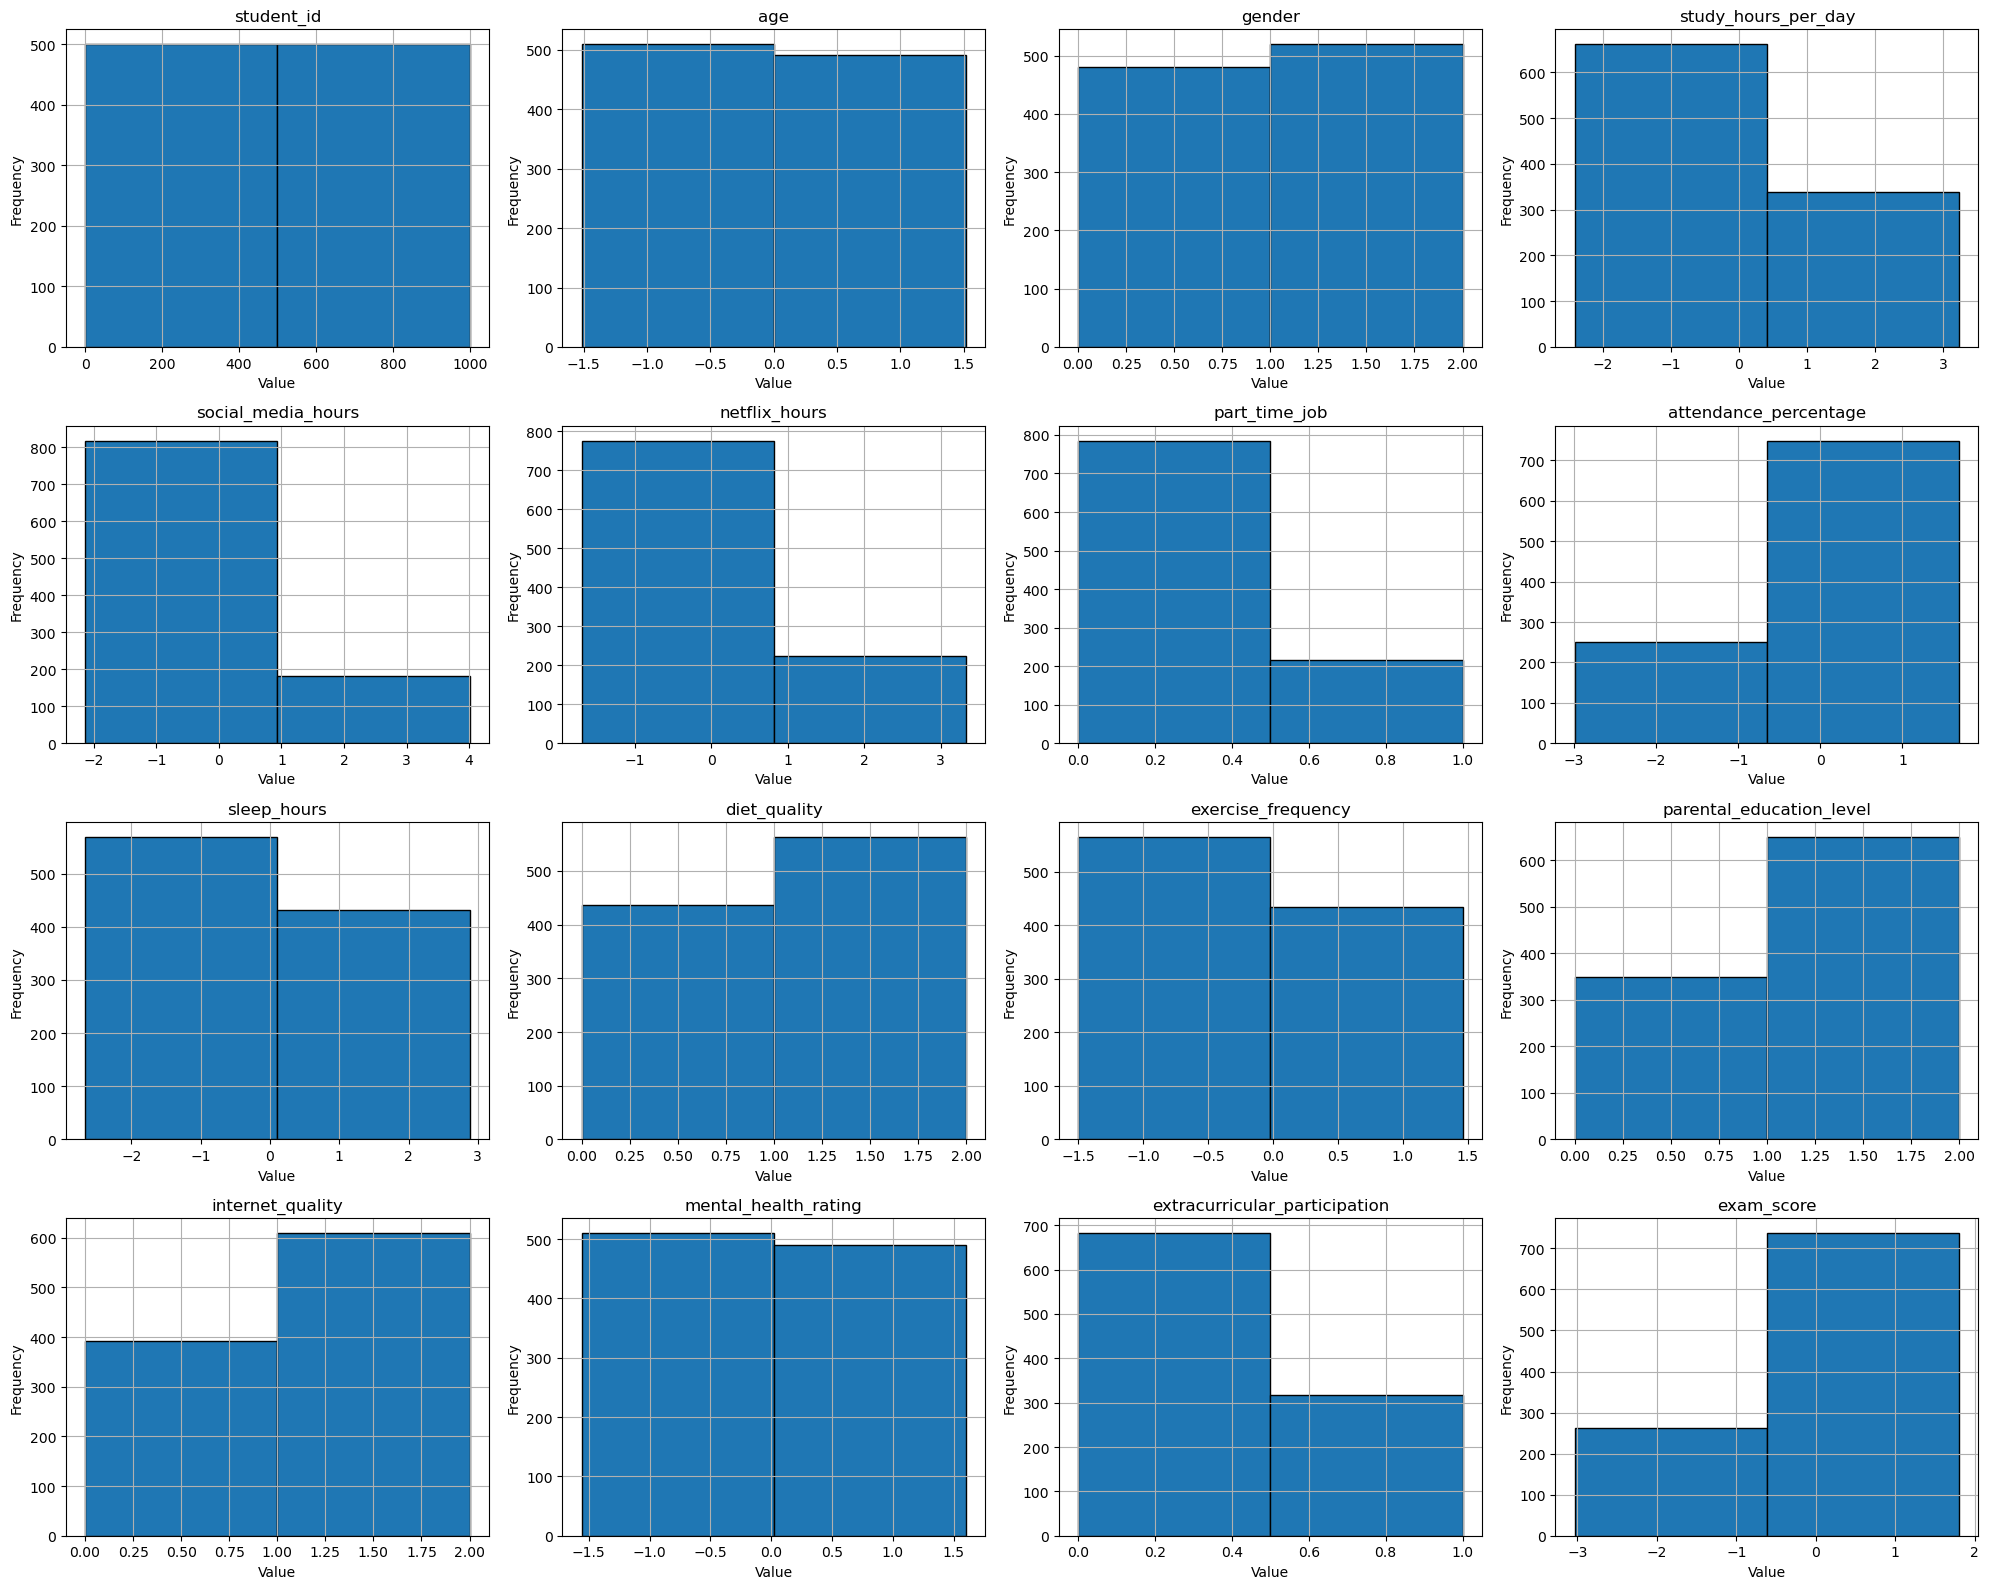

In [23]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]
# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diingikan
n_rows = -(-num_vars // n_cols) # Ceiling dividion untuk menentukana jumlah baris
# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()
# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=2, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

In [ ]:
Langkah 20 - Distribusi variabel pilihan.
Distribusi age, study_hours_per_day, social_media_hours, dan netflix_hours ditampilkan dengan histogram dan kurva KDE untuk melihat bentuk sebaran dan kecenderungan datanya.

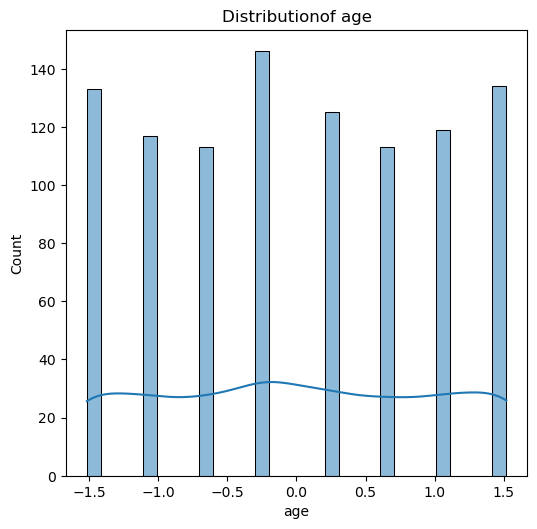

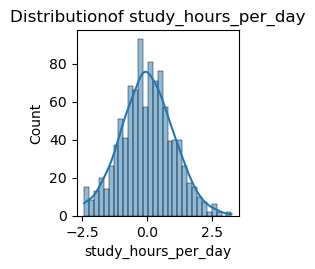

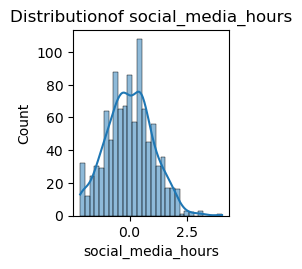

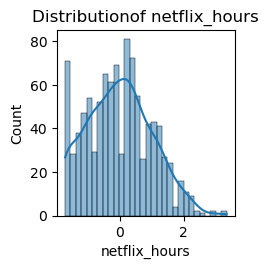

In [24]:
# Memvisualisasikan distribusi beberapa kolom serta melihat korelasi antara variabel numerik
import matplotlib.pyplot as plt
import seaborn as sns
#Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours']
plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distributionof {column}')
    plt.tight_layout()
    plt.show()

In [ ]:
Langkah 21 - Matriks korelasi.
Heatmap korelasi memperlihatkan kekuatan dan arah hubungan antarvariabel. Warna merah menunjukkan korelasi positif, biru korelasi negatif, dan warna netral korelasi lemah.

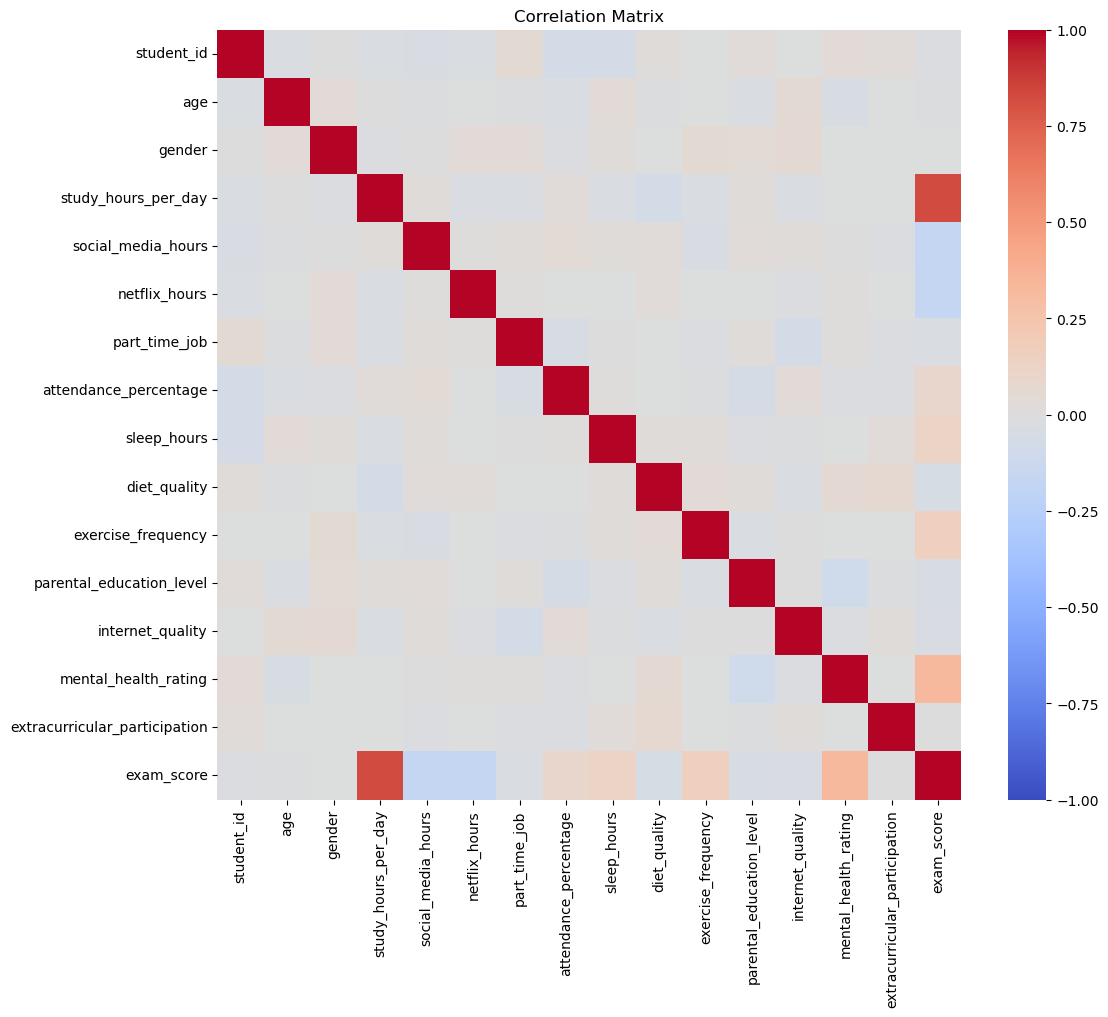

In [25]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [ ]:
Langkah 22 - Korelasi terhadap social_media_hours.
Korelasi semua variabel terhadap social_media_hours dihitung, diambil nilai absolutnya, lalu diurutkan dan ditampilkan dalam bar chart. Dari sini terlihat variabel mana yang paling berkaitan dengan lama penggunaan media sosial.

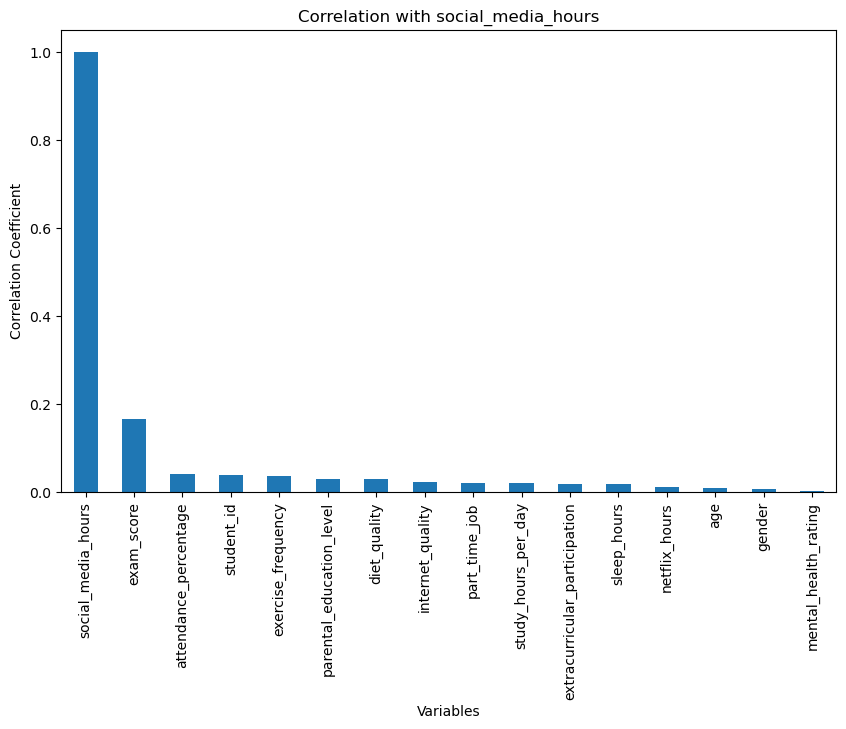

In [26]:
# Menghitung korelasi antara variabel target (social_media_hours) dan semua variabel lainnya
target_corr = df_lencoder.corr()['social_media_hours']
# Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with social_media_hours')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()